In [5]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import tensorflow as tf

tf.random.set_seed(3)

from tensorflow import keras
from keras.datasets import mnist
from tensorflow.math import confusion_matrix


In [6]:
from PIL import Image
from IPython.display import display

def cv2_imshow(img):
    if img is None:
        print('Error: Image is None (could not be loaded).')
        return
    if len(img.shape) == 2:
        display(Image.fromarray(img))
    else:
        display(Image.fromarray(
            cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ))


In [7]:
(X_train, Y_train), (X_test, Y_test) =  mnist.load_data()

In [8]:
print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [9]:
print(X_train[10])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  42 118 219 166 118 118   6
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 103 242 254 254 254 254 254  66
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  18 232 254 254 254 254 254 238
   70   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 104 244 254 224 254 254 254
  141   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0 207 254 210 25

In [10]:
print(X_train[10].shape)

(28, 28)


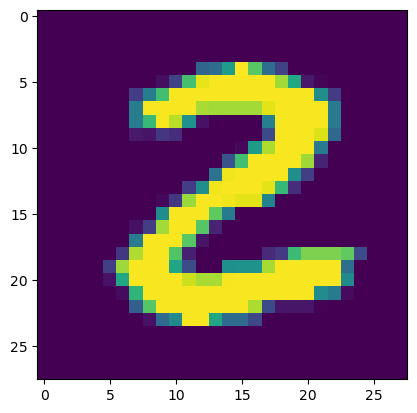

2


In [11]:
# displaying the image

plt.imshow(X_train[25])
plt.show()

# print the corresponding label
print(Y_train[25])

In [12]:
print(Y_train.shape, Y_test.shape)

(60000,) (10000,)


In [13]:
# unique values in Y_train
print(np.unique(Y_train))

# unique values in Y_test
print(np.unique(Y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


In [14]:
# scaling the values

X_train = X_train/255
X_test = X_test/255

In [15]:
print(X_train[10])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [16]:

model = keras.Sequential([
                          keras.layers.Flatten(input_shape=(28,28)),
                          keras.layers.Dense(50, activation='relu'),
                          keras.layers.Dense(50, activation='relu'),
                          keras.layers.Dense(10, activation='sigmoid')
])

c:\Users\aksha\.conda\envs\ml\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
model.compile(optimizer='adam',loss = 'sparse_categorical_crossentropy',metrics=['accuracy'])

In [18]:
model.fit(X_train, Y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9130 - loss: 0.3031
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9565 - loss: 0.1430
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9687 - loss: 0.1046
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9749 - loss: 0.0820
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9797 - loss: 0.0670
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9832 - loss: 0.0558
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9858 - loss: 0.0473
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9873 - loss: 0.0405
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9891 - loss: 0.0355
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9905 - loss: 0.0310


In [19]:
loss, accuracy = model.evaluate(X_test, Y_test)
print(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9699 - loss: 0.1229
0.9699000120162964


In [20]:
print(X_test.shape)

(10000, 28, 28)


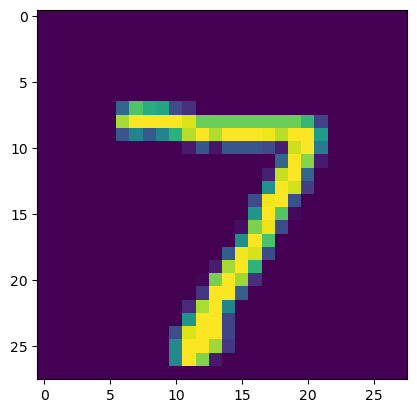

In [21]:
plt.imshow(X_test[0])
plt.show()

In [22]:
print(Y_test[0])

7


In [23]:
Y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [24]:
print(Y_pred.shape)

(10000, 10)


In [25]:
print(Y_pred[0])

[4.8066693e-05 6.1822509e-05 5.6618810e-01 9.8994225e-01 1.6676313e-07
 4.5155745e-02 4.6214224e-19 9.9999928e-01 1.7542129e-04 8.2324672e-01]


In [26]:
label_for_first_test_image = np.argmax(Y_pred[0])
print(label_for_first_test_image)

7


In [27]:
# converting the prediction probabilities to class label for all test data points
Y_pred_labels = [np.argmax(i) for i in Y_pred]
print(Y_pred_labels)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(5), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(3), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

In [28]:
conf_mat = confusion_matrix(Y_test, Y_pred_labels)

In [29]:
print(conf_mat)

tf.Tensor(
[[ 953    1    1    0    6    3    6    2    2    6]
 [   0 1122    2    2    0    1    2    2    4    0]
 [   3    4  985    8    8    0    3   14    6    1]
 [   0    0    3  983    0    4    0    9    4    7]
 [   0    0    2    0  964    0    1    3    1   11]
 [   3    1    1   14    4  858    2    2    5    2]
 [   4    3    0    2   10    5  931    0    3    0]
 [   0    2    5    3    2    1    0 1006    4    5]
 [   7    0    4   16    7    6    3    4  921    6]
 [   0    2    1    7   12    2    0    6    3  976]], shape=(10, 10), dtype=int32)


Text(0.5, 47.7222222222222, 'Predicted Labels')

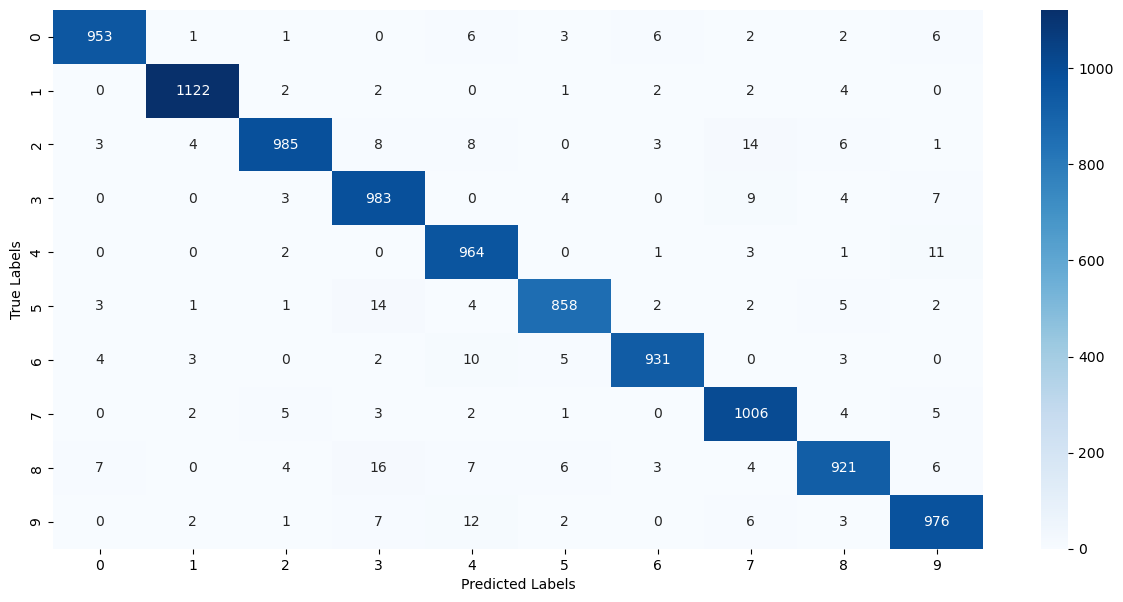

In [30]:
plt.figure(figsize=(15,7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.ylabel('True Labels')
plt.xlabel('Predicted Labels')

In [31]:
input_image_path = 'mnist__image.png'

input_image = cv2.imread(input_image_path)

In [32]:
print(input_image)

[[[113 113 113]
  [ 70  70  70]
  [ 72  72  72]
  ...
  [ 72  72  72]
  [ 73  73  73]
  [188 188 188]]

 [[ 70  70  70]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  9   9   9]
  [171 171 171]]

 [[ 72  72  72]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  9   9   9]
  [174 174 174]]

 ...

 [[ 72  72  72]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  9   9   9]
  [174 174 174]]

 [[ 72  72  72]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  9   9   9]
  [174 174 174]]

 [[ 72  72  72]
  [  0   0   0]
  [  0   0   0]
  ...
  [  0   0   0]
  [  9   9   9]
  [173 173 173]]]


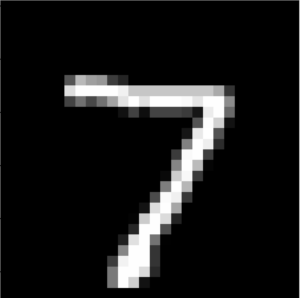

In [33]:
cv2_imshow(input_image)

In [34]:
input_image.shape

(298, 300, 3)

In [35]:
grayscale = cv2.cvtColor(input_image, cv2.COLOR_RGB2GRAY)

In [36]:
grayscale.shape

(298, 300)

In [37]:
input_image_resize = cv2.resize(grayscale, (28, 28))

In [38]:
input_image_resize.shape

(28, 28)

In [39]:
cv2_imshow(input_image_resize)

In [40]:
input_image_resize = input_image_resize/255

In [41]:
type(input_image_resize)

numpy.ndarray

In [42]:
image_reshaped = np.reshape(input_image_resize, [1,28,28])

In [43]:
input_prediction = model.predict(image_reshaped)
print(input_prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
[[4.8024816e-05 6.1822917e-05 5.6689000e-01 9.8992372e-01 1.6761183e-07
  4.5001298e-02 4.6641225e-19 9.9999928e-01 1.7698192e-04 8.2317090e-01]]


In [44]:
input_pred_label = np.argmax(input_prediction)

In [45]:
print(input_pred_label)

7


No path entered. Using default: mnist__image.png


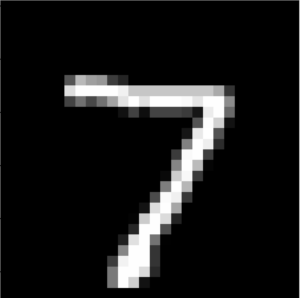

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
The Handwritten Digit is recognised as  7


In [46]:
import os

input_image_path = input('Path of the image to be predicted: ')

# Clean the path: remove whitespace and surrounding quotes (from copy-pasting on Windows)
input_image_path = input_image_path.strip().strip("'\"")

# Default to mnist__image.png if left blank
if not input_image_path and os.path.exists('mnist__image.png'):
    input_image_path = 'mnist__image.png'
    print(f"No path entered. Using default: {input_image_path}")

if not os.path.exists(input_image_path):
    print(f"Error: File not found at '{input_image_path}'. Please check the path and try again.")
else:
    input_image = cv2.imread(input_image_path)

    if input_image is None:
        print(f"Error: Could not read image at '{input_image_path}'. Make sure it is a valid image file.")
    else:
        cv2_imshow(input_image)

        grayscale = cv2.cvtColor(input_image, cv2.COLOR_RGB2GRAY)

        input_image_resize = cv2.resize(grayscale, (28, 28))

        input_image_resize = input_image_resize / 255

        image_reshaped = np.reshape(input_image_resize, [1, 28, 28])

        input_prediction = model.predict(image_reshaped)

        input_pred_label = np.argmax(input_prediction)

        print('The Handwritten Digit is recognised as ', input_pred_label)


In [47]:
W = model.get_weights()
np.savez(r"C:\Users\aksha\OneDrive\Desktop\MNIST\weights.npz",
            W1=W[0], b1=W[1], W2=W[2], b2=W[3], W3=W[4], b3=W[5])
print("saved")

saved
